NAME - RAJVEER SINGH

SECTION - B3_B4

ROLL NO - 57

# Diabetes Prediction
Target variable: `diabetes` (0 = non-diabetic, 1 = diabetic)

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier, VotingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from sklearn.svm import SVC
from xgboost import XGBClassifier

## 2. Load data

In [2]:
df = pd.read_csv('diabetes_prediction_dataset.csv')

In [3]:
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [4]:
df.tail()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0
99999,Female,57.0,0,0,current,22.43,6.6,90,0


In [5]:
df.shape

(100000, 9)

In [6]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='str')

In [7]:
df.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 8.0 MB


In [9]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [10]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [11]:
for col in ['gender', 'smoking_history']:
    print(df[col].value_counts(), "\n")

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64 

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64 



In [12]:
df['diabetes'].value_counts()

diabetes
0    91500
1     8500
Name: count, dtype: int64

## 3. Data cleaning

The raw file contains exact duplicate rows. If they are kept, identical records can land in both the train and test sets, which inflates the score (data leakage), so they are removed.

In [13]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 3854
Shape after removing duplicates: (96146, 9)


In [14]:
baseline = 1 - df['diabetes'].mean()
print(f"Diabetic share: {df['diabetes'].mean()*100:.1f}%")
print(f"Majority-class baseline accuracy: {baseline*100:.1f}%")

Diabetic share: 8.8%
Majority-class baseline accuracy: 91.2%


About 91% of patients are non-diabetic, so a model that always predicts "non-diabetic" already reaches ~91% accuracy. Accuracy is therefore reported next to diabetic-class recall and F1.

## 4. Exploratory data analysis

In [15]:
"""Plotting helpers shared by the notebook, the Streamlit app and the README assets."""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (auc, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_curve)

NAVY, TEAL, RED, SLATE, GRID = "#0F2A43", "#0E7C86", "#B3382C", "#5B6B7B", "#E2E7ED"
LABELS = {0: "Non-diabetic", 1: "Diabetic"}
PAL = {"Non-diabetic": TEAL, "Diabetic": RED}
LINE_COLORS = ["#0F2A43", "#0E7C86", "#B3382C", "#C27C0E", "#6C5B9E", "#2E7D5B", "#8C6D62", "#5B6B7B"]
NUMERIC = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
NICE = {"age": "Age (years)", "bmi": "BMI", "HbA1c_level": "HbA1c level (%)",
        "blood_glucose_level": "Blood glucose (mg/dL)"}


def set_style():
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white", "axes.edgecolor": GRID,
        "grid.color": "#EEF1F5", "axes.labelcolor": NAVY, "text.color": NAVY,
        "xtick.color": SLATE, "ytick.color": SLATE, "axes.titleweight": "bold",
        "axes.titlesize": 12, "axes.titlecolor": NAVY,
        "axes.spines.top": False, "axes.spines.right": False,
    })


def _labelled(df, target="diabetes", n=25000):
    d = df.sample(n, random_state=42) if len(df) > n else df
    return d.assign(**{target: d[target].map(LABELS)})


def class_distribution(df, target="diabetes"):
    counts = df[target].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(5, 3.6))
    bars = ax.bar([LABELS[i] for i in counts.index], counts.values, color=[TEAL, RED], width=0.55)
    for b, v in zip(bars, counts.values):
        ax.text(b.get_x() + b.get_width() / 2, v + counts.max() * 0.015,
                f"{v:,}  ({v / counts.sum() * 100:.1f}%)", ha="center", fontsize=10)
    ax.set_title("Class distribution")
    ax.set_ylabel("Records")
    ax.set_ylim(0, counts.max() * 1.15)
    fig.tight_layout()
    return fig


def numeric_distributions(df, target="diabetes"):
    d = _labelled(df, target)
    fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
    for ax, f in zip(axes.ravel(), NUMERIC):
        sns.kdeplot(data=d, x=f, hue=target, fill=True, common_norm=False, alpha=0.35,
                    palette=PAL, linewidth=1.5, ax=ax, legend=(f == NUMERIC[0]))
        ax.set_title(NICE[f])
        ax.set_xlabel("")
        ax.set_ylabel("")
    fig.suptitle("Feature distributions by outcome", fontsize=13, fontweight="bold")
    fig.tight_layout()
    return fig


def boxplots_by_outcome(df, target="diabetes"):
    d = _labelled(df, target)
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.8))
    for ax, f in zip(axes, NUMERIC):
        sns.boxplot(data=d, x=target, y=f, hue=target, palette=PAL, order=list(PAL), legend=False,
                    width=0.55, fliersize=2, linewidth=1, ax=ax)
        ax.set_title(NICE[f], fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", labelsize=8)
    fig.tight_layout()
    return fig


def categorical_rates(df, target="diabetes"):
    cols = [("gender", "Gender"), ("smoking_history", "Smoking history"),
            ("hypertension", "Hypertension"), ("heart_disease", "Heart disease")]
    fig, axes = plt.subplots(2, 2, figsize=(10, 6))
    for ax, (c, title) in zip(axes.ravel(), cols):
        rate = (df.groupby(c)[target].mean() * 100).sort_values(ascending=False)
        labels = [{0: "No", 1: "Yes"}.get(i, str(i)) for i in rate.index]
        bars = ax.bar(labels, rate.values, color=TEAL, width=0.6)
        for b, v in zip(bars, rate.values):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9)
        ax.axhline(df[target].mean() * 100, color=RED, ls="--", lw=1)
        ax.set_title(f"Diabetes rate by {title.lower()}")
        ax.set_ylim(0, max(rate.max() * 1.2, 1))
        ax.tick_params(axis="x", labelsize=9)
    fig.text(0.99, 0.005, "Dashed line = overall rate", ha="right", fontsize=8, color=SLATE)
    fig.tight_layout()
    return fig


def correlation_heatmap(df):
    cols = ["age", "hypertension", "heart_disease", "bmi", "HbA1c_level", "blood_glucose_level", "diabetes"]
    corr = df[cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    cmap = LinearSegmentedColormap.from_list("tr", [TEAL, "white", RED])
    fig, ax = plt.subplots(figsize=(7.5, 5.6))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, linewidths=1,
                linecolor="white", cbar_kws={"shrink": 0.8}, ax=ax, annot_kws={"size": 9})
    ax.set_title("Correlation matrix")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    return fig


def accuracy_bar(results, baseline=None):
    r = results.sort_values("Accuracy")
    colors = [TEAL if m == results.index[0] else "#B8C4D0" for m in r.index]
    fig, ax = plt.subplots(figsize=(7, 4.4))
    bars = ax.barh(r.index, r["Accuracy"], color=colors, height=0.6)
    for b, v in zip(bars, r["Accuracy"]):
        ax.text(v + 0.002, b.get_y() + b.get_height() / 2, f"{v * 100:.2f}%", va="center", fontsize=9)
    lo = (baseline - 0.02) if baseline else r["Accuracy"].min() - 0.03
    ax.set_xlim(lo, min(1.0, r["Accuracy"].max() + 0.02))
    if baseline:
        ax.axvline(baseline, color=RED, ls="--", lw=1.2)
        ax.text(baseline + 0.0005, -0.75, f"majority-class baseline {baseline * 100:.1f}%",
                color=RED, fontsize=8, va="center")
    ax.set_xlabel("Test accuracy")
    ax.set_title("Model accuracy (best highlighted)")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    return fig


def metrics_comparison(results):
    cols = [c for c in ["Accuracy", "F1 Score", "ROC-AUC", "Diabetic Recall"] if c in results.columns]
    r = results[cols]
    x = np.arange(len(r))
    w = 0.8 / len(cols)
    fig, ax = plt.subplots(figsize=(10.5, 4.4))
    for i, (c, col) in enumerate(zip(cols, [NAVY, TEAL, "#C27C0E", RED])):
        ax.bar(x + (i - (len(cols) - 1) / 2) * w, r[c], w, label=c, color=col)
    ax.set_xticks(x)
    ax.set_xticklabels(r.index, rotation=20, ha="right")
    ax.set_ylim(max(0, r.values.min() - 0.08), 1.0)
    ax.set_title("Model comparison across metrics", pad=30)
    ax.legend(frameon=False, ncol=len(cols), loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
    fig.tight_layout()
    return fig


def roc_curves(scores, y_test):
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    for (name, s), col in zip(scores.items(), LINE_COLORS):
        fpr, tpr, _ = roc_curve(y_test, s)
        ax.plot(fpr, tpr, color=col, lw=1.8, label=f"{name} ({auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "--", color=SLATE, lw=1)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title("ROC curves")
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    fig.tight_layout()
    return fig


def pr_curves(scores, y_test):
    fig, ax = plt.subplots(figsize=(6.5, 5.2))
    for (name, s), col in zip(scores.items(), LINE_COLORS):
        p, r, _ = precision_recall_curve(y_test, s)
        ax.plot(r, p, color=col, lw=1.8, label=f"{name} ({average_precision_score(y_test, s):.3f})")
    ax.axhline(float(np.mean(y_test)), ls="--", color=SLATE, lw=1)
    ax.set_xlabel("Recall (diabetic)")
    ax.set_ylabel("Precision (diabetic)")
    ax.set_title("Precision-recall curves")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    fig.tight_layout()
    return fig


def confusion_matrix_fig(y_true, y_pred, title="Confusion matrix"):
    cm = confusion_matrix(y_true, y_pred)
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f"{cm[i, j]:,}\n({pct[i, j]:.1f}%)" for j in range(2)] for i in range(2)])
    cmap = LinearSegmentedColormap.from_list("t", ["white", TEAL])
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=annot, fmt="", cmap=cmap, cbar=False, linewidths=1, linecolor="white",
                xticklabels=[LABELS[0], LABELS[1]], yticklabels=[LABELS[0], LABELS[1]],
                annot_kws={"size": 12}, ax=ax)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual (row % shown)")
    ax.set_title(title)
    fig.tight_layout()
    return fig


def importance_fig(importances, title="Feature importance (permutation)", xlabel="Drop in ROC-AUC when shuffled"):
    s = importances.sort_values()
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.barh(s.index, s.values, color=TEAL, height=0.6)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    return fig


def patient_position(df, patient, target="diabetes"):
    """Where a patient's HbA1c and glucose fall relative to the two classes."""
    d = _labelled(df, target)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    for ax, f in zip(axes, ["HbA1c_level", "blood_glucose_level"]):
        sns.kdeplot(data=d, x=f, hue=target, fill=True, common_norm=False, alpha=0.3,
                    palette=PAL, linewidth=1.3, ax=ax, legend=(f == "HbA1c_level"))
        ax.axvline(patient[f], color=NAVY, lw=2)
        ax.text(patient[f], ax.get_ylim()[1] * 0.97, "  patient", color=NAVY, fontsize=9, va="top")
        ax.set_title(NICE[f], fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")
    fig.tight_layout()
    return fig


set_style()

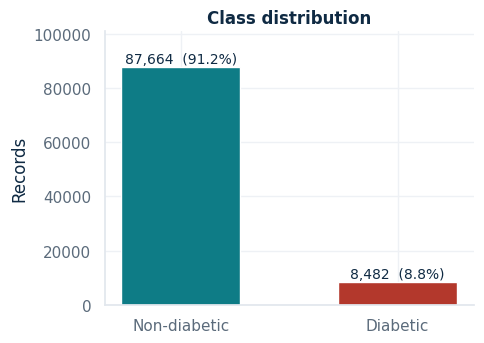

In [16]:
class_distribution(df);

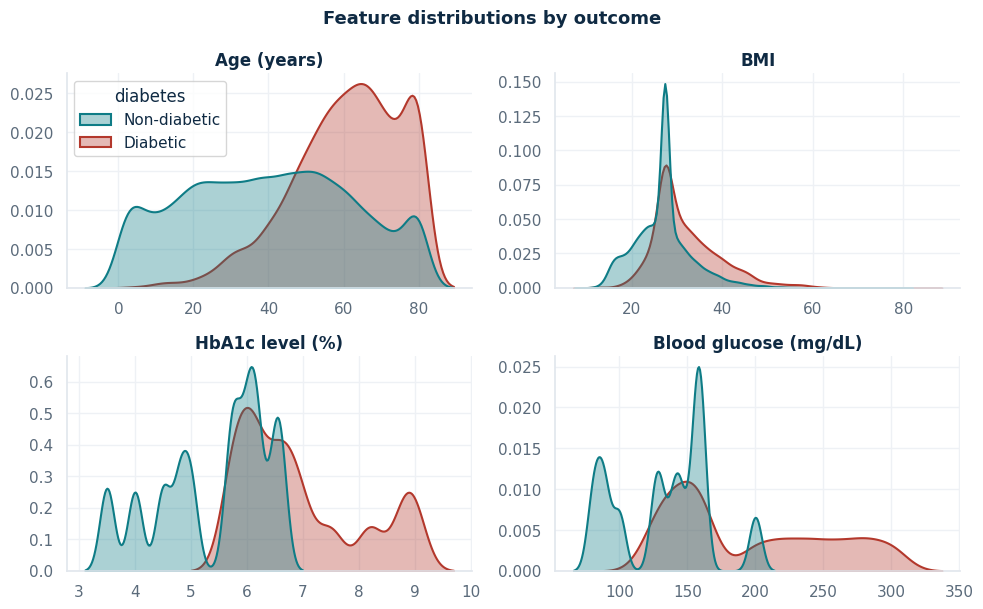

In [17]:
numeric_distributions(df);

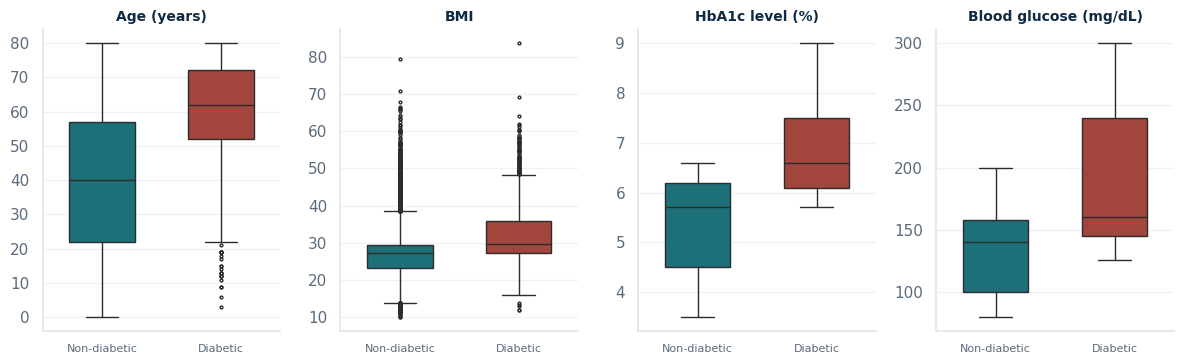

In [18]:
boxplots_by_outcome(df);

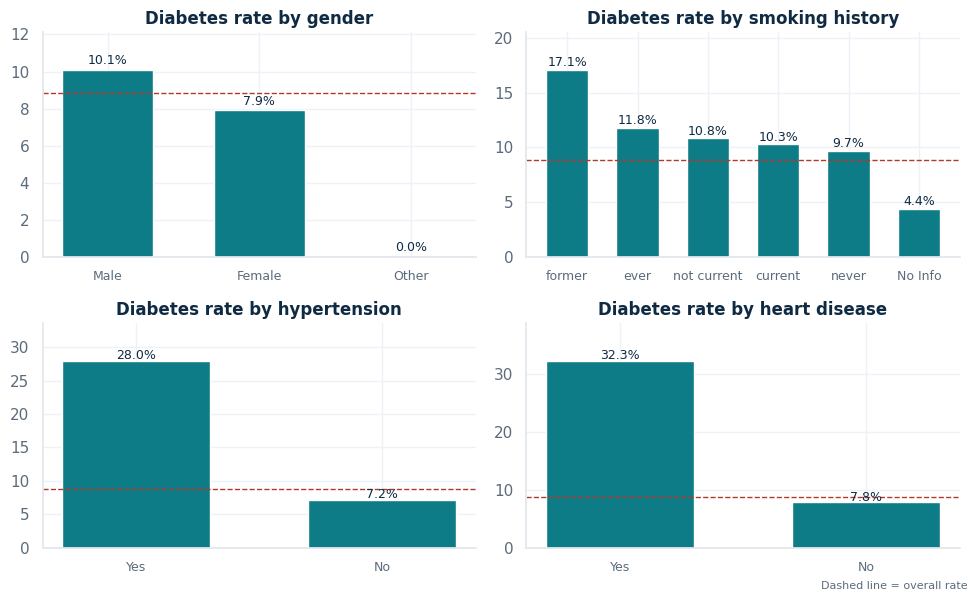

In [19]:
categorical_rates(df);

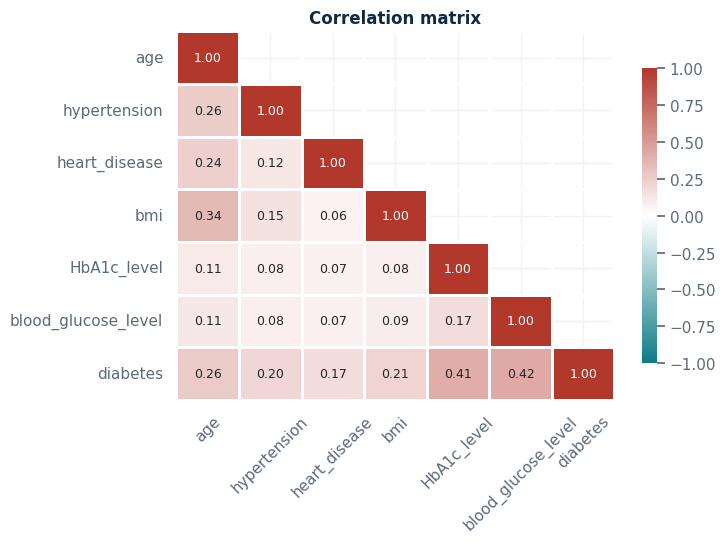

In [20]:
correlation_heatmap(df);

## 5. Train-test split and preprocessing

Categorical columns are one-hot encoded and numeric columns are standardised inside a `ColumnTransformer`, so every model below is a single pipeline that accepts the raw columns. The split is stratified to keep the class ratio equal in train and test.

In [21]:
X = df.drop(['diabetes'], axis=1)
y = df['diabetes']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

In [23]:
numeric_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
categorical_cols = ['gender', 'smoking_history']

def make_preprocessor():
    return ColumnTransformer(
        [("num", StandardScaler(), numeric_cols),
         ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)],
        remainder="passthrough")   # hypertension and heart_disease are already 0/1

In [24]:
print("X Train:", X_train.shape)
print("X Test:", X_test.shape)
print("Y Train:", y_train.shape)
print("Y Test:", y_test.shape)

X Train: (67302, 8)
X Test: (28844, 8)
Y Train: (67302,)
Y Test: (28844,)


## 6. Models

### Decision Tree

In [25]:
dt = Pipeline([("prep", make_preprocessor()), ("clf", DecisionTreeClassifier(random_state=42))])

In [26]:
dt.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [27]:
pred_dt = dt.predict(X_test)

In [28]:
dt_accuracy = accuracy_score(y_test, pred_dt)
dt_precision = precision_score(y_test, pred_dt, average="weighted", zero_division=0)
dt_recall = recall_score(y_test, pred_dt, average="weighted", zero_division=0)
dt_f1 = f1_score(y_test, pred_dt, average="weighted", zero_division=0)
print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1 Score :", dt_f1)

Accuracy : 0.9482388018305367
Precision: 0.9499460395642543
Recall   : 0.9482388018305367
F1 Score : 0.9490126352931751


### Logistic Regression

In [29]:
lo = Pipeline([("prep", make_preprocessor()), ("clf", LogisticRegression(max_iter=1000))])

In [30]:
lo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [31]:
pred_lo = lo.predict(X_test)

In [32]:
lo_accuracy = accuracy_score(y_test, pred_lo)
lo_precision = precision_score(y_test, pred_lo, average="weighted", zero_division=0)
lo_recall = recall_score(y_test, pred_lo, average="weighted", zero_division=0)
lo_f1 = f1_score(y_test, pred_lo, average="weighted", zero_division=0)
print("Accuracy :", lo_accuracy)
print("Precision:", lo_precision)
print("Recall   :", lo_recall)
print("F1 Score :", lo_f1)

Accuracy : 0.9585355706559423
Precision: 0.9560938977570257
Recall   : 0.9585355706559423
F1 Score : 0.9556033768497535


### Random Forest

In [33]:
rf = Pipeline([("prep", make_preprocessor()), ("clf", RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))])

In [34]:
rf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [35]:
pred_rf = rf.predict(X_test)

In [36]:
rf_accuracy = accuracy_score(y_test, pred_rf)
rf_precision = precision_score(y_test, pred_rf, average="weighted", zero_division=0)
rf_recall = recall_score(y_test, pred_rf, average="weighted", zero_division=0)
rf_f1 = f1_score(y_test, pred_rf, average="weighted", zero_division=0)
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Accuracy : 0.9710511718208293
Precision: 0.9719220183655989
Recall   : 0.9710511718208293
F1 Score : 0.968444510674174


### KNN

In [37]:
knn = Pipeline([("prep", make_preprocessor()), ("clf", KNeighborsClassifier(n_neighbors=5, n_jobs=-1))])

In [38]:
knn.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [39]:
knn_pred = knn.predict(X_test)

In [40]:
knn_accuracy = accuracy_score(y_test, knn_pred)
knn_precision = precision_score(y_test, knn_pred, average="weighted", zero_division=0)
knn_recall = recall_score(y_test, knn_pred, average="weighted", zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, average="weighted", zero_division=0)
print("Accuracy :", knn_accuracy)
print("Precision:", knn_precision)
print("Recall   :", knn_recall)
print("F1 Score :", knn_f1)

Accuracy : 0.9595756483150741
Precision: 0.9576472636364284
Recall   : 0.9595756483150741
F1 Score : 0.9561405496269383


### SVC

In [41]:
svc = Pipeline([("prep", make_preprocessor()), ("clf", SVC(random_state=42))])

In [42]:
svc.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [43]:
svc_pred = svc.predict(X_test)

In [44]:
svc_accuracy = accuracy_score(y_test, svc_pred)
svc_precision = precision_score(y_test, svc_pred, average="weighted", zero_division=0)
svc_recall = recall_score(y_test, svc_pred, average="weighted", zero_division=0)
svc_f1 = f1_score(y_test, svc_pred, average="weighted", zero_division=0)
print("Accuracy :", svc_accuracy)
print("Precision:", svc_precision)
print("Recall   :", svc_recall)
print("F1 Score :", svc_f1)

Accuracy : 0.9638746359728193
Precision: 0.9646754742481102
Recall   : 0.9638746359728193
F1 Score : 0.9598056605540478


### XGBoost

In [45]:
xgb = Pipeline([("prep", make_preprocessor()), ("clf", XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, eval_metric="logloss", n_jobs=-1))])

In [46]:
xgb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [47]:
xgb_pred = xgb.predict(X_test)

In [48]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred, average="weighted", zero_division=0)
xgb_recall = recall_score(y_test, xgb_pred, average="weighted", zero_division=0)
xgb_f1 = f1_score(y_test, xgb_pred, average="weighted", zero_division=0)
print("Accuracy :", xgb_accuracy)
print("Precision:", xgb_precision)
print("Recall   :", xgb_recall)
print("F1 Score :", xgb_f1)

Accuracy : 0.9711205103314381
Precision: 0.9717946716779061
Recall   : 0.9711205103314381
F1 Score : 0.9686030049698368


In [49]:
print("Classification Report")
print(classification_report(y_test, xgb_pred, target_names=["Non-diabetic", "Diabetic"]))

Classification Report
              precision    recall  f1-score   support

Non-diabetic       0.97      1.00      0.98     26299
    Diabetic       0.99      0.68      0.81      2545

    accuracy                           0.97     28844
   macro avg       0.98      0.84      0.89     28844
weighted avg       0.97      0.97      0.97     28844



### Voting Classifier (soft voting)

In [50]:
voting_model = Pipeline([("prep", make_preprocessor()), ("clf", VotingClassifier(
    estimators=[("dt", DecisionTreeClassifier(random_state=42)),
                ("knn", KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
                ("lo", LogisticRegression(max_iter=1000)),
                ("rf", RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)),
                ("xgb", XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, eval_metric="logloss", n_jobs=-1))],
    voting="soft"))])
voting_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [51]:
voting_pred = voting_model.predict(X_test)

In [52]:
v_accuracy = accuracy_score(y_test, voting_pred)
v_precision = precision_score(y_test, voting_pred, average="weighted", zero_division=0)
v_recall = recall_score(y_test, voting_pred, average="weighted", zero_division=0)
v_f1 = f1_score(y_test, voting_pred, average="weighted", zero_division=0)
print("Accuracy :", v_accuracy)
print("Precision:", v_precision)
print("Recall   :", v_recall)
print("F1 Score :", v_f1)

Accuracy : 0.9705311329912634
Precision: 0.9703673130360413
Recall   : 0.9705311329912634
F1 Score : 0.9683024638299276


### Stacking Classifier

In [53]:
stacking_model = Pipeline([("prep", make_preprocessor()), ("clf", StackingClassifier(
    estimators=[("dt", DecisionTreeClassifier(random_state=42)),
                ("rf", RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)),
                ("knn", KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
                ("xgb", XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42, eval_metric="logloss", n_jobs=-1))],
    final_estimator=LogisticRegression(max_iter=1000), cv=3))])
stacking_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [54]:
pred_stack = stacking_model.predict(X_test)

In [55]:
stack_accuracy = accuracy_score(y_test, pred_stack)
stack_precision = precision_score(y_test, pred_stack, average="weighted", zero_division=0)
stack_recall = recall_score(y_test, pred_stack, average="weighted", zero_division=0)
stack_f1 = f1_score(y_test, pred_stack, average="weighted", zero_division=0)
print("Accuracy :", stack_accuracy)
print("Precision:", stack_precision)
print("Recall   :", stack_recall)
print("F1 Score :", stack_f1)

Accuracy : 0.969456386076827
Precision: 0.9685230188623867
Recall   : 0.969456386076827
F1 Score : 0.9675914260988154


## 7. Model comparison

In [56]:
models = {
    "Decision Tree": dt, "Logistic Regression": lo, "Random Forest": rf, "KNN": knn,
    "SVC": svc, "XGBoost": xgb, "Voting (soft)": voting_model, "Stacking": stacking_model,
}

def positive_scores(m, X):
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)

rows, scores = [], {}
for name, m in models.items():
    pred = m.predict(X_test)
    scores[name] = positive_scores(m, X_test)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores[name]),
        "Diabetic Recall": recall_score(y_test, pred, pos_label=1),
        "Diabetic F1": f1_score(y_test, pred, pos_label=1),
    })

results = pd.DataFrame(rows).sort_values(["Accuracy", "F1 Score"], ascending=False).set_index("Model")
print("Model Comparison:")
results.style.format("{:.4f}").highlight_max(color="#DCEFF1")

Model Comparison:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Diabetic Recall,Diabetic F1
Model,,,,,,,
XGBoost,0.9711,0.9718,0.9711,0.9686,0.9769,0.6770,0.8053
Random Forest,0.9711,0.9719,0.9711,0.9684,0.9668,0.6723,0.8039
Voting (soft),0.9705,0.9704,0.9705,0.9683,0.9692,0.6916,0.8055
Stacking,0.9695,0.9685,0.9695,0.9676,0.9749,0.7092,0.8038
SVC,0.9639,0.9647,0.9639,0.9598,0.9373,0.5992,0.7454
KNN,0.9596,0.9576,0.9596,0.9561,0.9024,0.6149,0.7286
Logistic Regression,0.9585,0.9561,0.9585,0.9556,0.9597,0.6314,0.7288
Decision Tree,0.9482,0.9499,0.9482,0.9490,0.8549,0.7411,0.7164


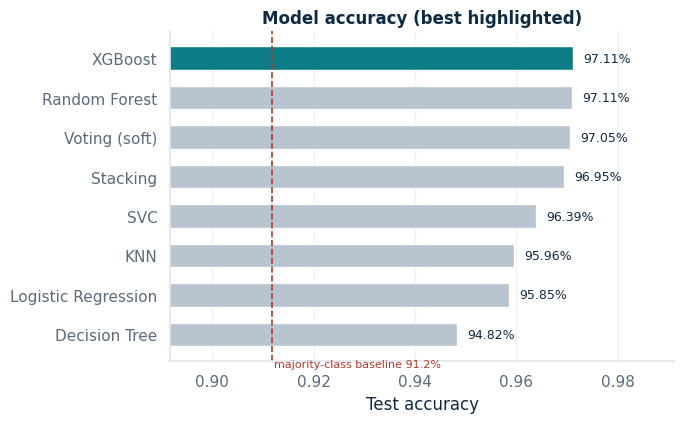

In [57]:
accuracy_bar(results, baseline=1 - y_test.mean());

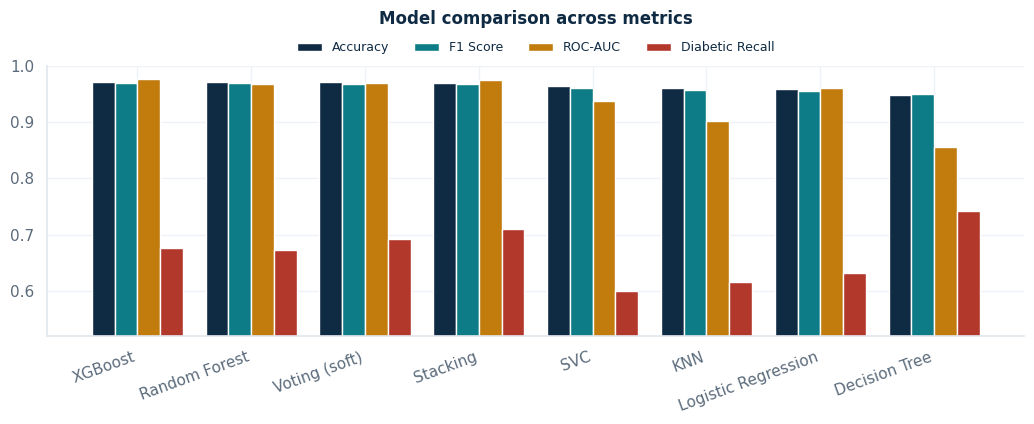

In [58]:
metrics_comparison(results);

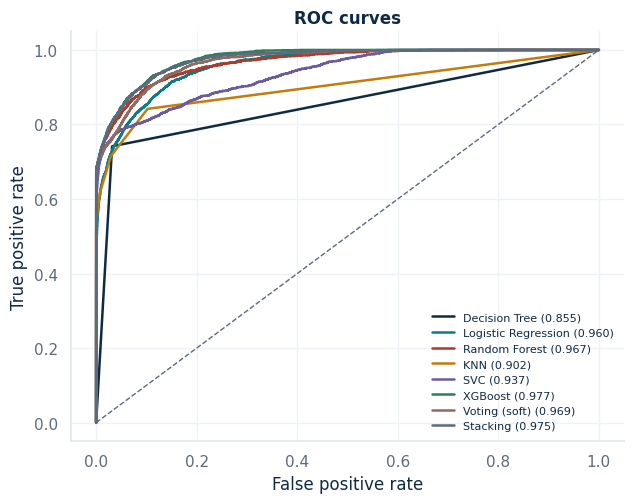

In [59]:
roc_curves(scores, y_test);

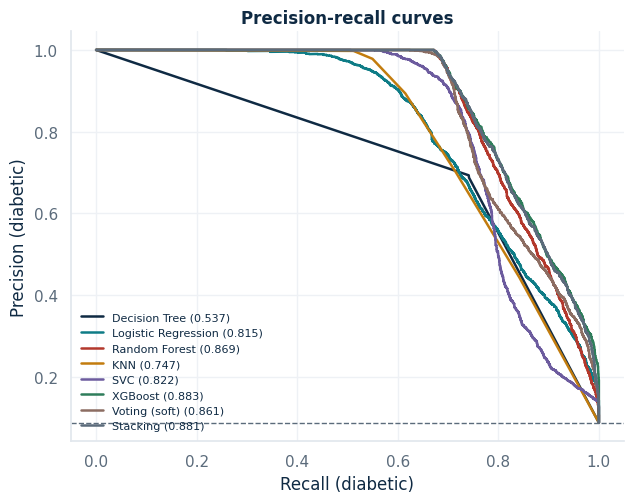

In [60]:
pr_curves(scores, y_test);

## 8. Best model

In [61]:
best_model_name = results.index[0]
best_model = models[best_model_name]
print("Best model:", best_model_name)
print(f"Accuracy  : {results.loc[best_model_name, 'Accuracy']:.4f}")

Best model: XGBoost
Accuracy  : 0.9711


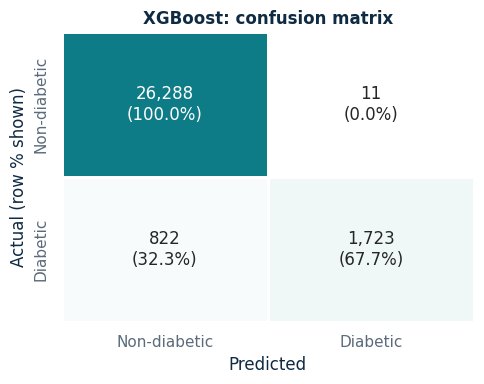

In [62]:
best_pred = best_model.predict(X_test)
confusion_matrix_fig(y_test, best_pred, f"{best_model_name}: confusion matrix");

In [63]:
print(classification_report(y_test, best_pred, target_names=['Non-diabetic', 'Diabetic']))

              precision    recall  f1-score   support

Non-diabetic       0.97      1.00      0.98     26299
    Diabetic       0.99      0.68      0.81      2545

    accuracy                           0.97     28844
   macro avg       0.98      0.84      0.89     28844
weighted avg       0.97      0.97      0.97     28844



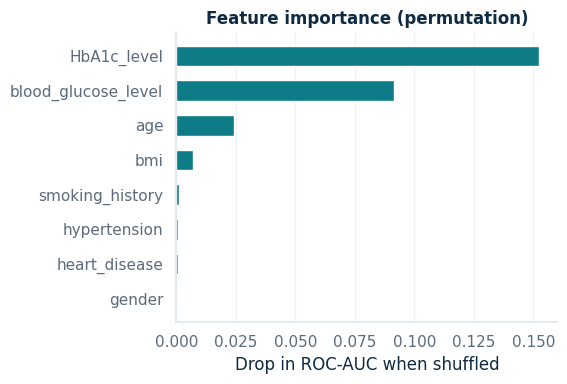

In [64]:
imp = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=42, scoring="roc_auc")
importances = pd.Series(imp.importances_mean, index=X.columns)
importance_fig(importances);

## 9. Save the best model

In [65]:
joblib.dump(best_model, "best_diabetes_model.pkl")
print("Saved best_diabetes_model.pkl")

Saved best_diabetes_model.pkl


## 10. Gradio app (optional demo)

Loads the model saved above with `joblib.load`, the same way a deployed app would.

In [ ]:
!pip install -U gradio -q

In [ ]:
import gradio as gr

model = joblib.load("best_diabetes_model.pkl")

def assess(gender, age, hypertension, heart_disease, smoking, bmi, hba1c, glucose):
    row = pd.DataFrame([[gender, age, int(hypertension == "Yes"), int(heart_disease == "Yes"),
                         smoking, bmi, hba1c, glucose]], columns=list(X.columns))
    p = float(model.predict_proba(row)[0][1])
    band = "Low" if p < 0.20 else "Moderate" if p < 0.50 else "High"
    return ({"Diabetic": p, "Non-diabetic": 1 - p},
            f"Model: {best_model_name}  |  Probability: {p*100:.1f}%  |  Risk band: {band}")

theme = gr.themes.Base(primary_hue="teal", neutral_hue="slate",
                       font=[gr.themes.GoogleFont("Inter"), "sans-serif"])

with gr.Blocks(title="Diabetes Risk Screening") as demo:
    gr.Markdown(f"# Diabetes Risk Screening\nPowered by the best of eight compared models: **{best_model_name}**.")
    with gr.Row():
        with gr.Column():
            gender = gr.Dropdown(["Female", "Male", "Other"], value="Female", label="Gender")
            age = gr.Number(label="Age (years)", value=45)
            hypertension = gr.Radio(["No", "Yes"], value="No", label="Hypertension")
            heart_disease = gr.Radio(["No", "Yes"], value="No", label="Heart disease")
        with gr.Column():
            smoking = gr.Dropdown(["never", "No Info", "former", "current", "not current", "ever"],
                                  value="never", label="Smoking history")
            bmi = gr.Number(label="BMI", value=27.0)
            hba1c = gr.Number(label="HbA1c level (%)", value=5.5)
            glucose = gr.Number(label="Blood glucose (mg/dL)", value=120)
    btn = gr.Button("Run assessment", variant="primary")
    out_label = gr.Label(label="Result", num_top_classes=2)
    out_text = gr.Textbox(label="Summary", interactive=False)
    btn.click(assess, [gender, age, hypertension, heart_disease, smoking, bmi, hba1c, glucose],
              [out_label, out_text])
    gr.Markdown("*For educational use only. Not a medical diagnosis.*")

demo.launch(theme=theme, share=True)